📉 Échantillonnage : 1 ligne sur 10 (100,000 lignes analysées)


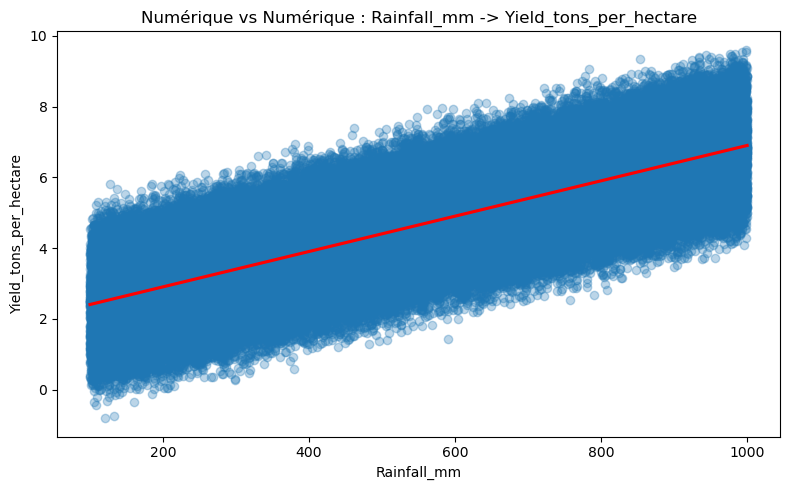

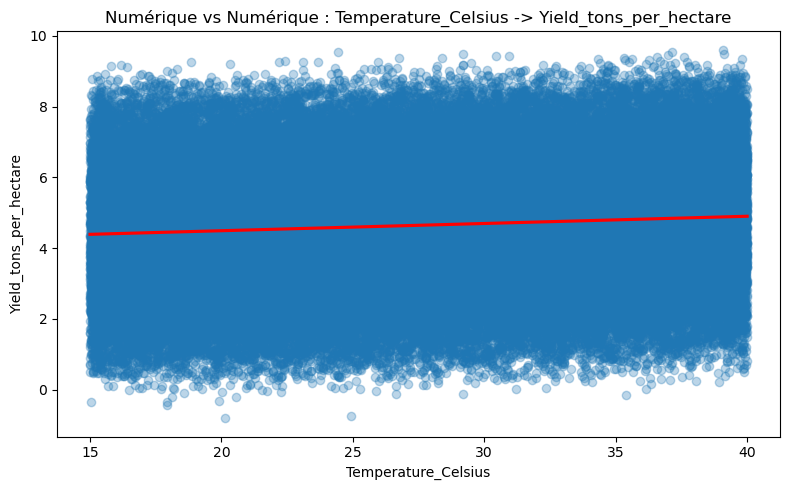

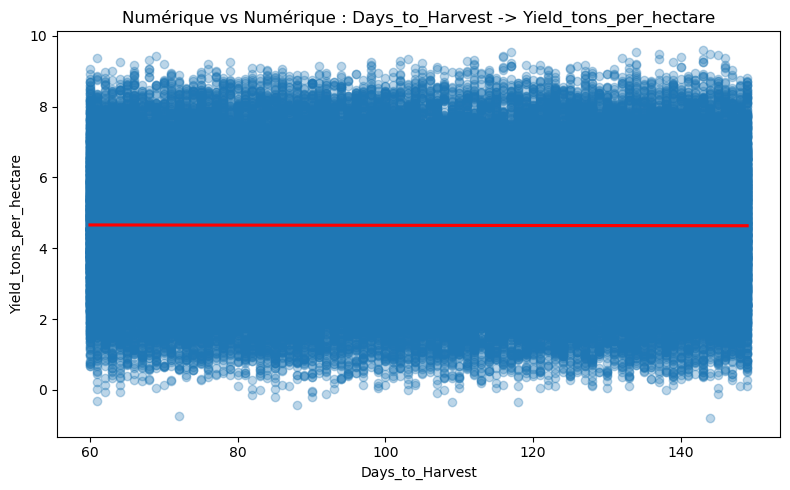

C:\Users\jacob\AppData\Local\Temp\ipykernel_11568\697523000.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette="Set2")


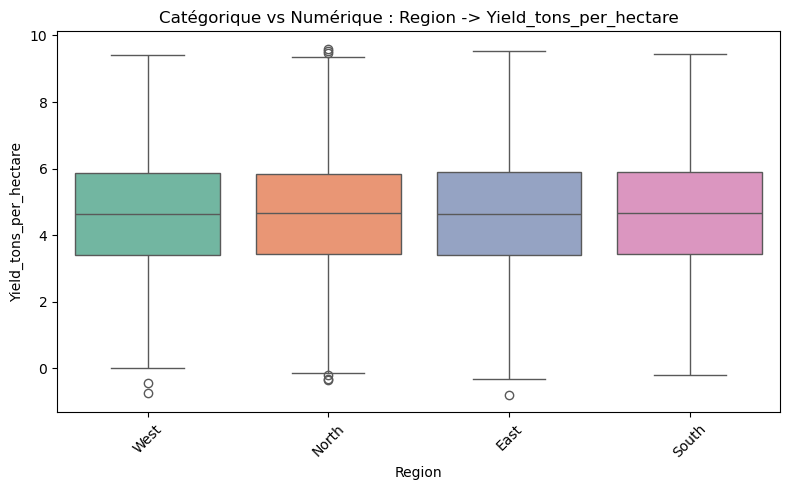

C:\Users\jacob\AppData\Local\Temp\ipykernel_11568\697523000.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette="Set2")


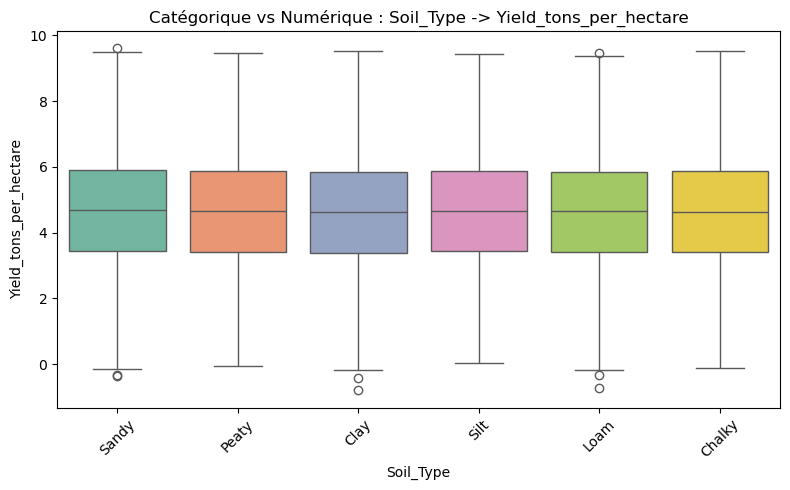

C:\Users\jacob\AppData\Local\Temp\ipykernel_11568\697523000.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette="Set2")


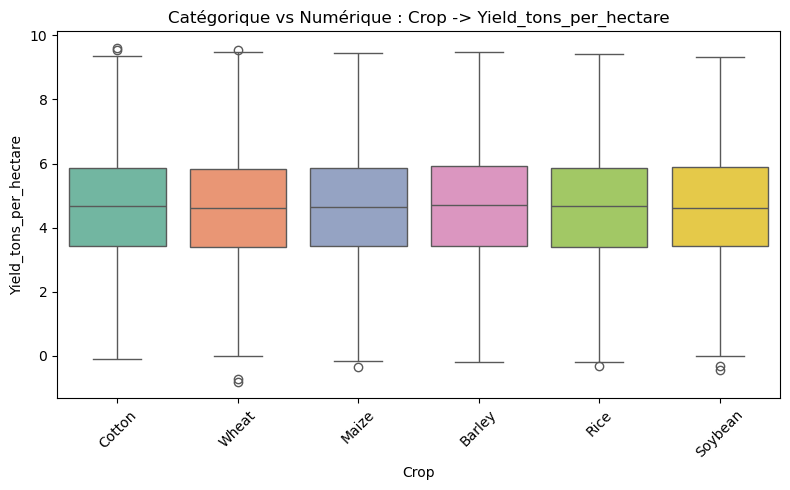

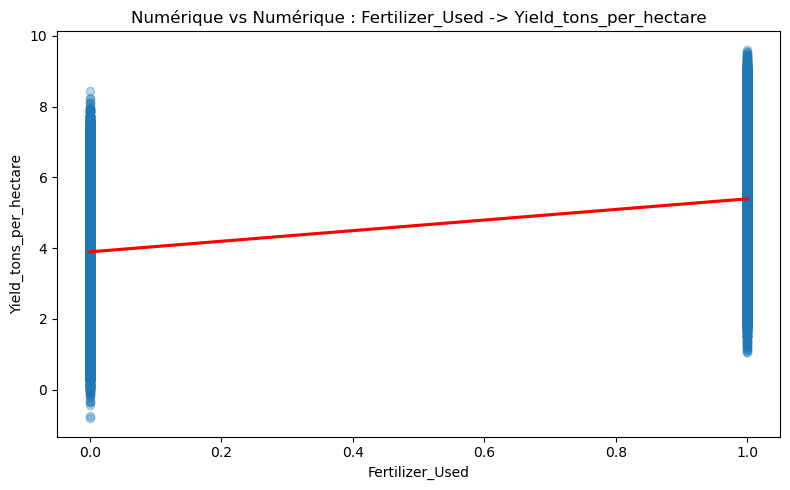

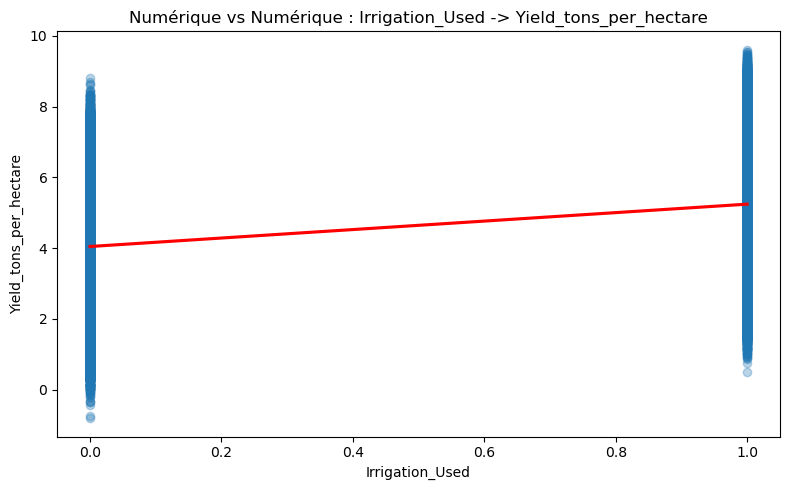

C:\Users\jacob\AppData\Local\Temp\ipykernel_11568\697523000.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette="Set2")


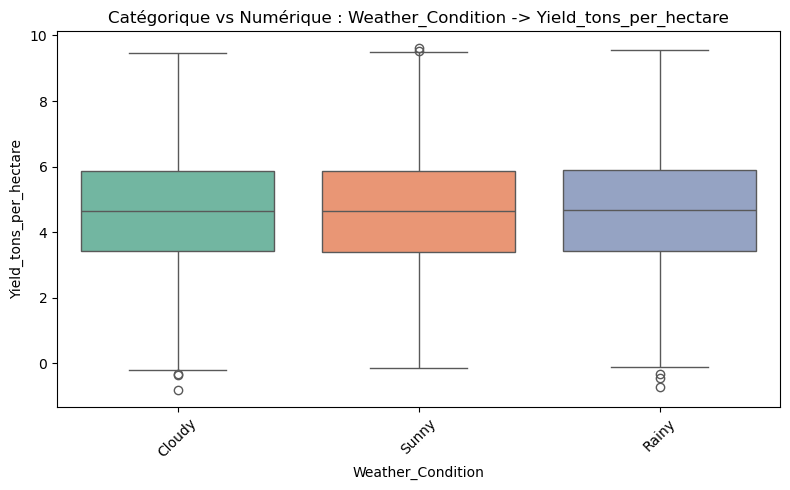

In [4]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def analyser_impact_variables(csv_path, features, target, reduction_factor=10):
  path = Path(csv_path)
  if not path.exists():
    raise FileNotFoundError(f"Le fichier {csv_path} est introuvable.")

  df = pd.read_csv(path)

  # Réduction du DataFrame si demandé
  if reduction_factor > 1:
    df = df.iloc[::reduction_factor].reset_index(drop=True)
    print(
        f"📉 Échantillonnage : 1 ligne sur {reduction_factor}"
        f" ({len(df):,} lignes analysées)"
    )

  # Vérification des colonnes
  colonnes_manquantes = [
      col for col in features + [target] if col not in df.columns
  ]
  if colonnes_manquantes:
    raise ValueError(f"Colonnes absentes : {colonnes_manquantes}")

  for col in features:
    plt.figure(figsize=(8, 5))

    if pd.api.types.is_numeric_dtype(df[col]) and pd.api.types.is_numeric_dtype(
        df[target]
    ):
      sns.regplot(
          data=df,
          x=col,
          y=target,
          scatter_kws={"alpha": 0.3},
          line_kws={"color": "red"},
      )
      plt.title(f"Numérique vs Numérique : {col} -> {target}")

    elif not pd.api.types.is_numeric_dtype(
        df[col]
    ) and pd.api.types.is_numeric_dtype(df[target]):
      sns.boxplot(data=df, x=col, y=target, palette="Set2")
      plt.xticks(rotation=45)
      plt.title(f"Catégorique vs Numérique : {col} -> {target}")

    else:
      sns.countplot(data=df, x=col, hue=target, palette="Set2")
      plt.xticks(rotation=45)
      plt.title(f"Croisement : {col} vs {target}")

    plt.tight_layout()
    plt.show()

# --- Exemple d'utilisation ---
analyser_impact_variables(
     csv_path="../data/raw/crop_yield.csv",
     features=["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Region", "Soil_Type", "Crop", 
               "Fertilizer_Used", "Irrigation_Used", "Weather_Condition"],
     target="Yield_tons_per_hectare",
     reduction_factor=10,  # Garde 1 ligne sur 10 (100k lignes au lieu d'1M)
)


 